#  Customer Churn Prediction: Logistic Regression and Optimizer Comparison

## 1. Import Libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)


## 2. Load Dataset

In [2]:
df = pd.read_csv(
    "/kaggle/input/datasets/hassanobaya/telecom-customers-churn/Telecom Customers Churn.csv"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 3. Exploratory Data Analysis (EDA)
### 3.1 Dataset Overview

In [3]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# First 5 rows
display(df.head())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3.2 Dataset Information and Data Types

In [4]:
# Dataset information
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

### 3.3 Statistical Summary

In [5]:
# Statistical summary
print("Statistical Summary:")
display(df.describe(include="all").T)

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.4 Check Duplicate Rows

In [6]:
# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


### 3.5 Check Missing Values

In [7]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Display rows with missing TotalCharges
display(df[df["TotalCharges"].isnull()])

Missing Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


### 3.6 Investigate Missing Values

In [8]:
# Check tenure for rows with missing TotalCharges
print("Tenure of Customers with Missing TotalCharges:")
print(df.loc[df["TotalCharges"].isnull(), "tenure"])

Tenure of Customers with Missing TotalCharges:
488     0
753     0
936     0
1082    0
1340    0
3331    0
3826    0
4380    0
5218    0
6670    0
6754    0
Name: tenure, dtype: int64


### 3.7 Target Variable Distribution

In [9]:
print("Churn Distribution:")
print(df["Churn"].value_counts())

print("\nChurn Percentages:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


### 3.8 Data Visualization

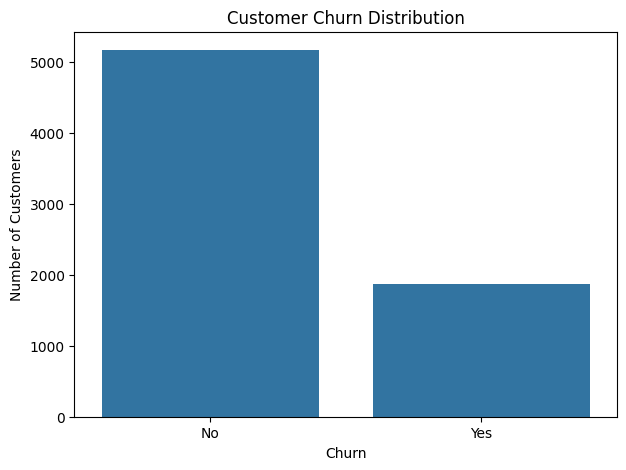

In [10]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

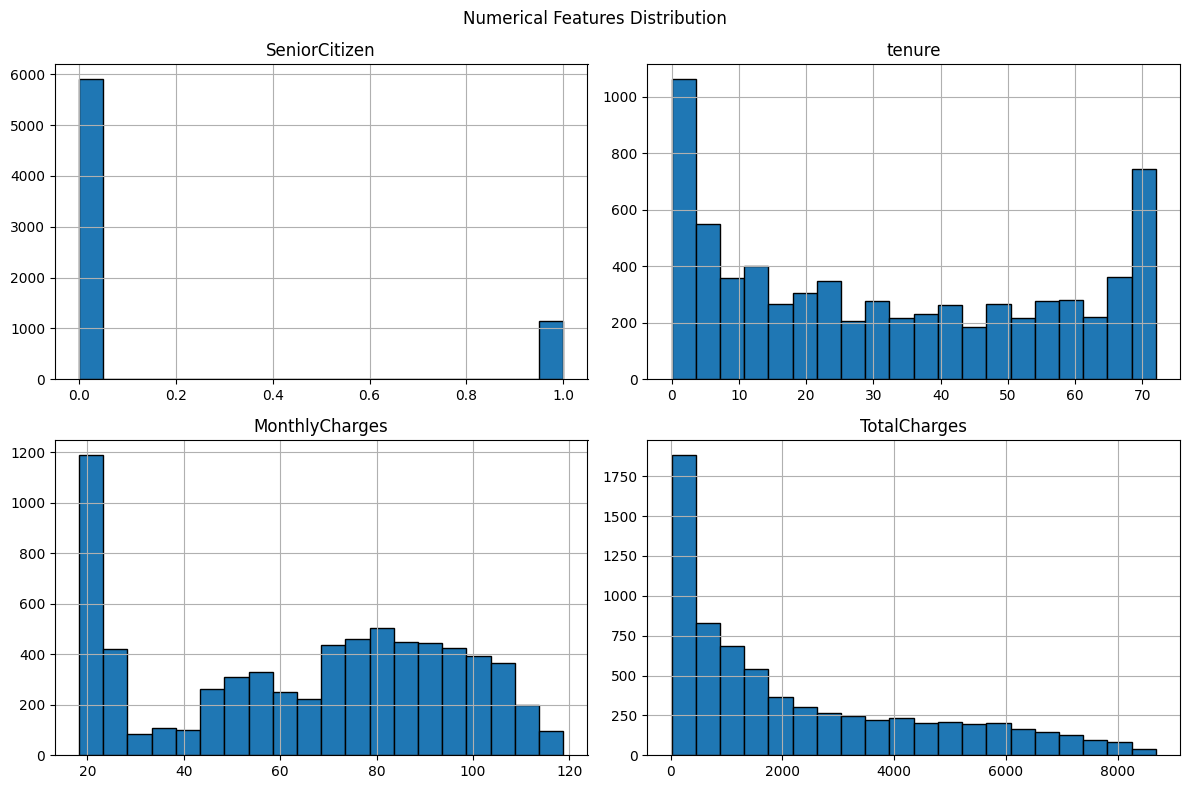

In [11]:
numerical_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns

df[numerical_cols].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Numerical Features Distribution")
plt.tight_layout()
plt.show()

## 4. Data Preprocessing

### 4.1 Handle Missing Values

In [12]:
# Handle missing values in TotalCharges
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Check missing values after handling
print("Missing Values After Handling:")
print(df.isnull().sum())

Missing Values After Handling:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


### 4.2 Remove Unnecessary Columns

In [13]:
# Remove customerID column
df = df.drop("customerID", axis=1)

# Display updated dataset
print("Dataset Shape After Removing customerID:", df.shape)

Dataset Shape After Removing customerID: (7043, 20)


### 4.3 Encode Target Variable

In [14]:
# Encode target variable
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Check target values
print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


### 4.4 Encode Categorical Features

In [15]:
# Apply One-Hot Encoding
df = pd.get_dummies(
    df,
    drop_first=True,
    dtype=int
)

# Display encoded dataset
print("Dataset Shape After Encoding:", df.shape)
display(df.head())

Dataset Shape After Encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


### 4.5 Separate Features and Target

In [16]:
# Separate features and target
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7043, 30)
Target Shape: (7043,)


### 4.6 Split Data into Training and Testing Sets

In [17]:
from sklearn.model_selection import train_test_split

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 30)
X_test: (1409, 30)
y_train: (5634,)
y_test: (1409,)


### 4.7 Feature Scaling (Standardization)

In [18]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train = scaler.fit_transform(X_train)

# Transform testing data
X_test = scaler.transform(X_test)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (5634, 30)
Testing Data Shape: (1409, 30)


## 5. Logistic Regression Implementation (From Scratch)
### 5.1 Prepare Data for the Model

In [19]:
# Convert target arrays to NumPy and reshape
y_train = np.array(y_train).reshape(-1, 1)
y_test = np.array(y_test).reshape(-1, 1)

# Check data shapes
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 30)
y_train shape: (5634, 1)
X_test shape: (1409, 30)
y_test shape: (1409, 1)


### 5.2 Initialize Model Parameters

In [20]:
# Initialize model parameters
def initialize_parameters(n_features):

    W = np.zeros((n_features, 1))
    b = 0.0

    return W, b


# Initialize parameters
W, b = initialize_parameters(X_train.shape[1])

print("Weights Shape:", W.shape)
print("Bias:", b)

Weights Shape: (30, 1)
Bias: 0.0


### 5.3 Sigmoid Activation Function

In [21]:
# Sigmoid activation function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

### 5.4 Forward Propagation

In [22]:
# Forward Propagation
def forward_propagation(X, W, b):

    z = np.dot(X, W) + b

    A = sigmoid(z)

    return A

### 5.5 Binary Cross-Entropy Loss Function

In [23]:
# Binary Cross-Entropy Loss
def compute_loss(y, A):

    epsilon = 1e-15

    A = np.clip(A, epsilon, 1 - epsilon)

    loss = -np.mean(
        y * np.log(A) +
        (1 - y) * np.log(1 - A)
    )

    return loss

### 5.6 Compute Gradients (Backward Propagation)

In [24]:
# Compute Gradients
def compute_gradients(X, y, A):

    m = X.shape[0]

    error = A - y

    dW = np.dot(X.T, error) / m

    db = np.sum(error) / m

    return dW, db

### 5.7 Prediction Function

In [25]:
# Prediction Function
def predict(X, W, b):

    A = forward_propagation(X, W, b)

    predictions = (A >= 0.5).astype(int)

    return predictions

## 6. Optimizers Implementation
### 6.1 Mini-Batch Gradient Descent

In [26]:
# Mini Batch Optimizer
def train_minibatch(X, y, batch_size=32, learning_rate=0.01,
                    epochs=1000, use_momentum=False, beta=0.9, seed=42):

    # Get number of training examples and features
    m, n = X.shape

    # Initialize model parameters
    W, b = initialize_parameters(n)

    # Initialize momentum velocities
    velocity_W = np.zeros_like(W)
    velocity_b = 0.0

    # Store loss values after each epoch
    loss_history = []

    # Create random number generator
    rng = np.random.default_rng(seed)

    # Training loop
    for epoch in range(epochs):

        # Shuffle training examples
        indices = rng.permutation(m)

        # Process data in mini-batches
        for start in range(0, m, batch_size):

            # Get indices for the current mini-batch
            batch_indices = indices[start:start + batch_size]

            # Select the current mini-batch
            X_batch = X[batch_indices]
            y_batch = y[batch_indices]

            # Forward propagation
            A = forward_propagation(X_batch, W, b)

            # Compute gradients
            dW, db = compute_gradients(X_batch, y_batch, A)

            # Update parameters using Momentum or standard Mini-Batch GD
            if use_momentum:

                # Update momentum velocities
                velocity_W = beta * velocity_W + (1 - beta) * dW
                velocity_b = beta * velocity_b + (1 - beta) * db

                # Update weights and bias
                W = W - learning_rate * velocity_W
                b = b - learning_rate * velocity_b

            else:

                # Update weights and bias
                W = W - learning_rate * dW
                b = b - learning_rate * db

        # Calculate loss using the entire training dataset
        A_all = forward_propagation(X, W, b)
        loss = compute_loss(y, A_all)

        # Store loss for the current epoch
        loss_history.append(loss)

    # Return trained parameters and loss history
    return W, b, loss_history

### 6.2 Train Mini-Batch

In [27]:
# Train Mini-Batch GD without Momentum
W_minibatch, b_minibatch, loss_minibatch = train_minibatch(
    X_train, y_train,
    batch_size=32,
    learning_rate=0.01,
    epochs=1000,
    use_momentum=False
)

# Train Mini-Batch GD with Momentum
W_minibatch_momentum, b_minibatch_momentum, loss_minibatch_momentum = train_minibatch(
    X_train, y_train,
    batch_size=32,
    learning_rate=0.01,
    epochs=1000,
    use_momentum=True
)

# Display final training losses
print("Mini-Batch GD Final Loss:", loss_minibatch[-1])
print("Mini-Batch GD with Momentum Final Loss:", loss_minibatch_momentum[-1])

Mini-Batch GD Final Loss: 0.41281431592685053
Mini-Batch GD with Momentum Final Loss: 0.41274870473454245


### 6.3 Visualize Training Loss

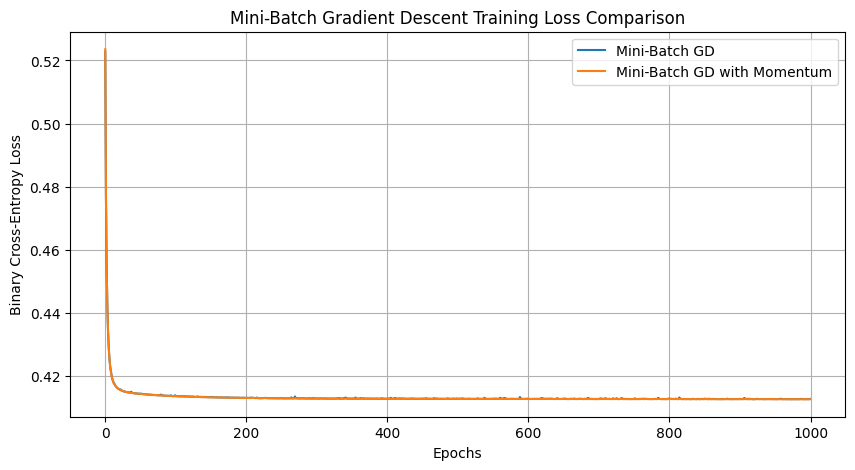

In [28]:
# Plot training loss for both Mini-Batch versions
plt.figure(figsize=(10, 5))

plt.plot(loss_minibatch, label="Mini-Batch GD")
plt.plot(loss_minibatch_momentum, label="Mini-Batch GD with Momentum")

plt.title("Mini-Batch Gradient Descent Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")

plt.legend()
plt.grid(True)
plt.show()

## 7. Model Evaluation

In [29]:
# Make predictions using Mini-Batch GD
y_pred_minibatch = predict(X_test, W_minibatch, b_minibatch)

# Calculate evaluation metrics
accuracy_minibatch = accuracy_score(y_test, y_pred_minibatch)
precision_minibatch = precision_score(y_test, y_pred_minibatch, zero_division=0)
recall_minibatch = recall_score(y_test, y_pred_minibatch, zero_division=0)
f1_minibatch = f1_score(y_test, y_pred_minibatch, zero_division=0)

# Calculate test loss
A_minibatch = forward_propagation(X_test, W_minibatch, b_minibatch)
loss_minibatch_test = compute_loss(y_test, A_minibatch)

# Display results
print("Mini-Batch GD Evaluation Results")
print("Accuracy:", accuracy_minibatch)
print("Precision:", precision_minibatch)
print("Recall:", recall_minibatch)
print("F1-score:", f1_minibatch)
print("Loss:", loss_minibatch_test)

# Make predictions using Mini-Batch GD with Momentum
y_pred_minibatch_momentum = predict(X_test, W_minibatch_momentum, b_minibatch_momentum)

# Calculate evaluation metrics
accuracy_minibatch_momentum = accuracy_score(y_test, y_pred_minibatch_momentum)
precision_minibatch_momentum = precision_score(y_test, y_pred_minibatch_momentum, zero_division=0)
recall_minibatch_momentum = recall_score(y_test, y_pred_minibatch_momentum, zero_division=0)
f1_minibatch_momentum = f1_score(y_test, y_pred_minibatch_momentum, zero_division=0)

# Calculate test loss
A_minibatch_momentum = forward_propagation(X_test, W_minibatch_momentum, b_minibatch_momentum)
loss_minibatch_momentum_test = compute_loss(y_test, A_minibatch_momentum)

# Display results
print("Mini-Batch GD with Momentum Evaluation Results")
print("Accuracy:", accuracy_minibatch_momentum)
print("Precision:", precision_minibatch_momentum)
print("Recall:", recall_minibatch_momentum)
print("F1-score:", f1_minibatch_momentum)
print("Loss:", loss_minibatch_momentum_test)

Mini-Batch GD Evaluation Results
Accuracy: 0.8055358410220014
Precision: 0.6524390243902439
Recall: 0.5721925133689839
F1-score: 0.6096866096866097
Loss: 0.4203825493157775
Mini-Batch GD with Momentum Evaluation Results
Accuracy: 0.8048261178140526
Precision: 0.6542056074766355
Recall: 0.5614973262032086
F1-score: 0.60431654676259
Loss: 0.4200631866419124
